# 05 — Model Comparison, Selection & Prediction System

Compares every model from notebook 04, selects the best one, saves the final artifacts (model + TF-IDF vectorizer + label encoder) and tests the `predict()` function in `src/predict.py`.

In [1]:
import json, shutil, os
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
res = json.load(open('reports/results.json'))
cols = ['features','test_accuracy','precision','recall','f1','f1_macro','val_accuracy','fit_seconds','predict_ms_per_1000']
df = pd.DataFrame({k: {c: v[c] for c in cols} for k, v in res.items()}).T
for c in cols[1:]: df[c] = df[c].astype(float)
df = df.sort_values('f1', ascending=False)
df.round(4)

,features,test_accuracy,precision,recall,f1,f1_macro,val_accuracy,fit_seconds,predict_ms_per_1000
linear_svc,TF-IDF,0.9236,0.9235,0.9236,0.9234,0.9234,0.9292,2.4,0.2
logistic_regression,TF-IDF,0.9200,0.9199,0.9200,0.9199,0.9199,0.9257,12.8,0.2
naive_bayes,TF-IDF,0.9076,0.9076,0.9076,0.9074,0.9074,0.9175,0.0,0.3
logistic_regression_bow,BoW,0.9024,0.9023,0.9024,0.9023,0.9023,0.9108,3.2,0.2
naive_bayes_bow,BoW,0.9018,0.9015,0.9018,0.9016,0.9016,0.9112,0.0,0.2
random_forest,TF-IDF (chi2 top 20k),0.8989,0.8987,0.8989,0.8986,0.8986,0.9030,219.6,56.1
gradient_boosting,TF-IDF + SVD(200),0.8904,0.8900,0.8904,0.8901,0.8901,0.8967,49.9,34.5


## Metric comparison

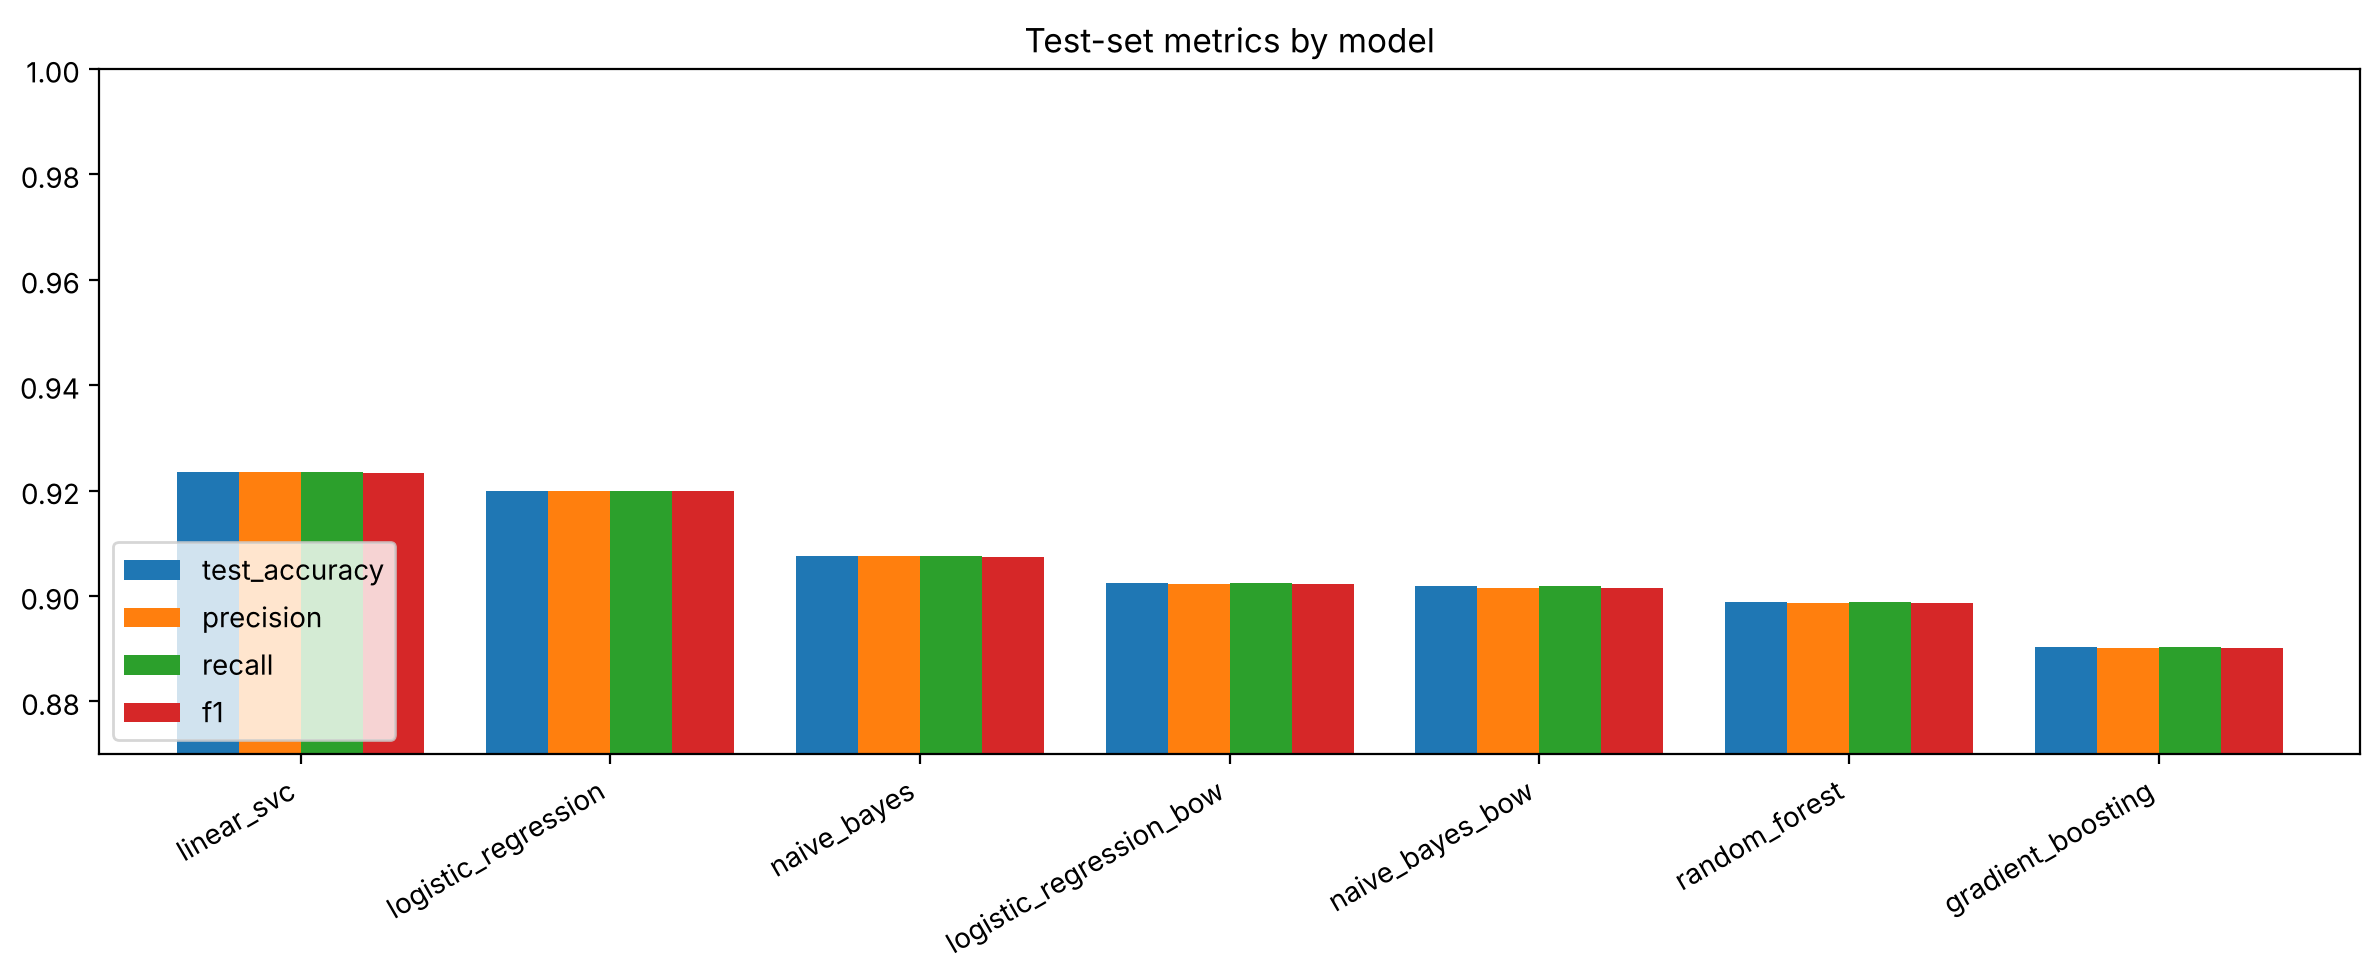

In [2]:
ax = df[['test_accuracy','precision','recall','f1']].plot(kind='bar', figsize=(12, 5), width=.8)
ax.set_ylim(df[['test_accuracy','precision','recall','f1']].min().min() - .02, 1); ax.set_title('Test-set metrics by model'); ax.legend(loc='lower left'); plt.xticks(rotation=30, ha='right'); plt.tight_layout()
plt.savefig('reports/model_comparison.png', dpi=110); plt.show()

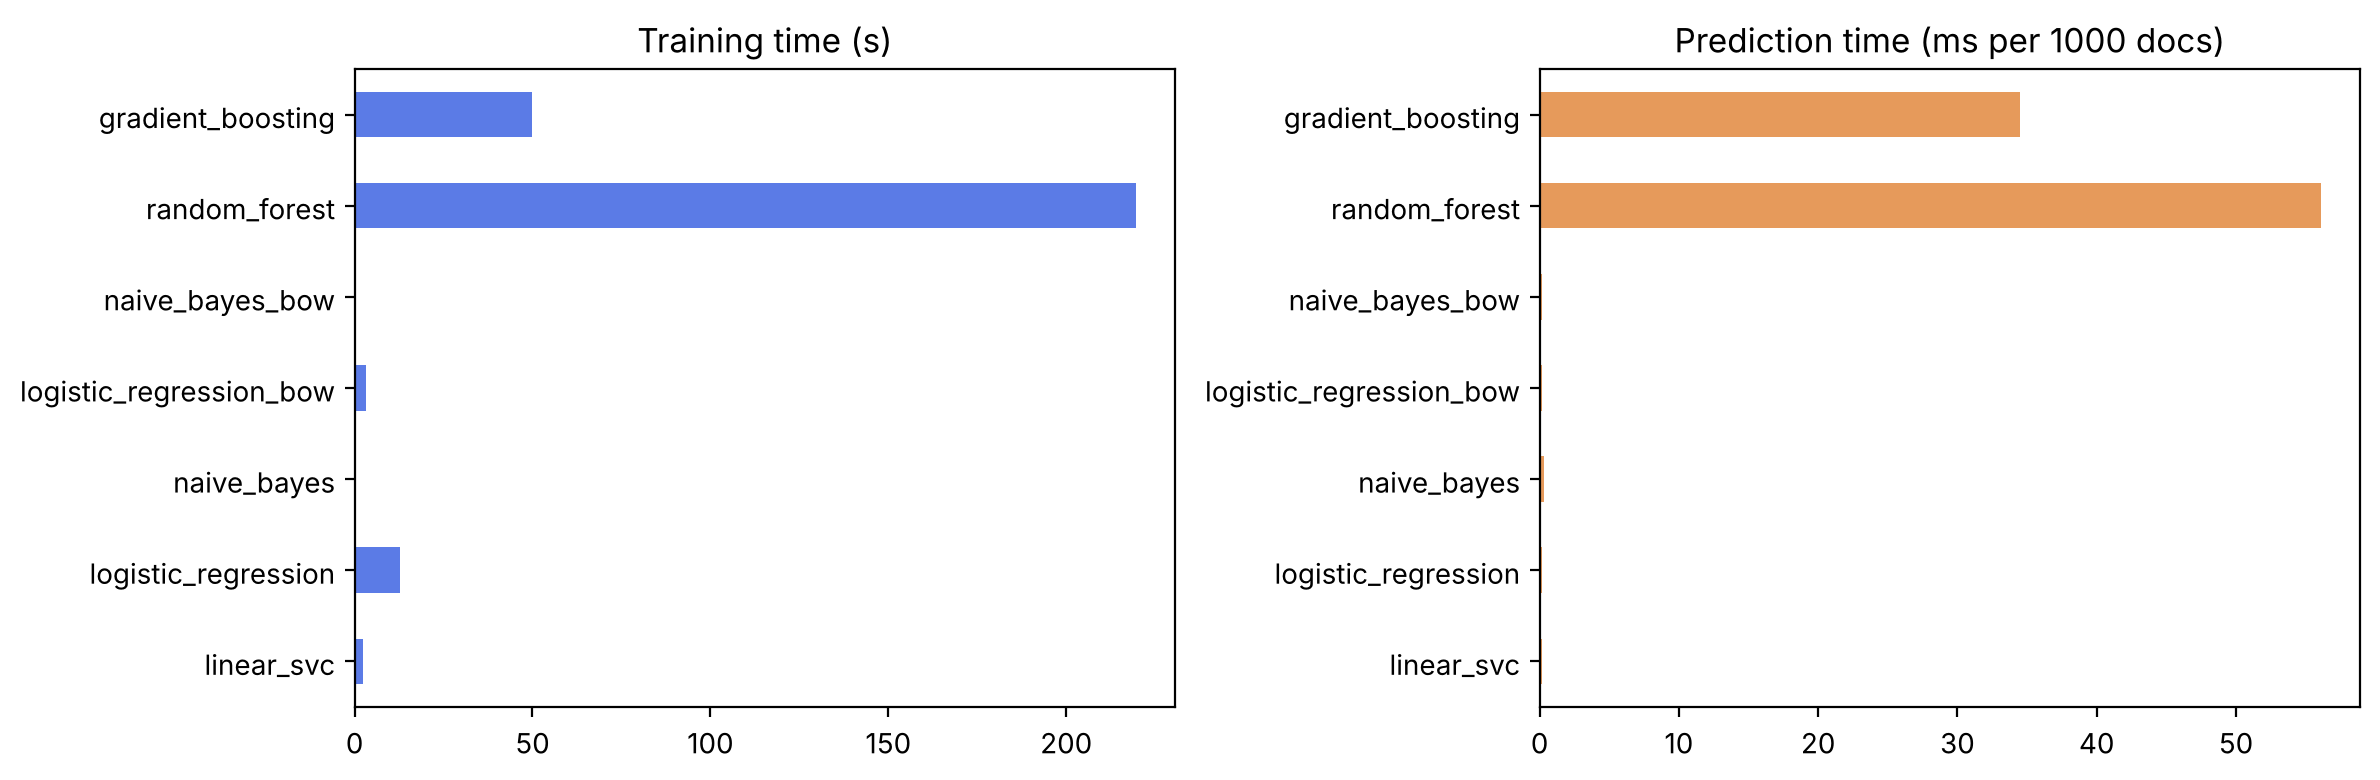

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df['fit_seconds'].plot(kind='barh', ax=ax[0], color='#5b7be6', title='Training time (s)')
df['predict_ms_per_1000'].plot(kind='barh', ax=ax[1], color='#e69a5b', title='Prediction time (ms per 1000 docs)')
plt.tight_layout(); plt.savefig('reports/model_speed.png', dpi=110); plt.show()

## Per-class F1 and confusion matrices

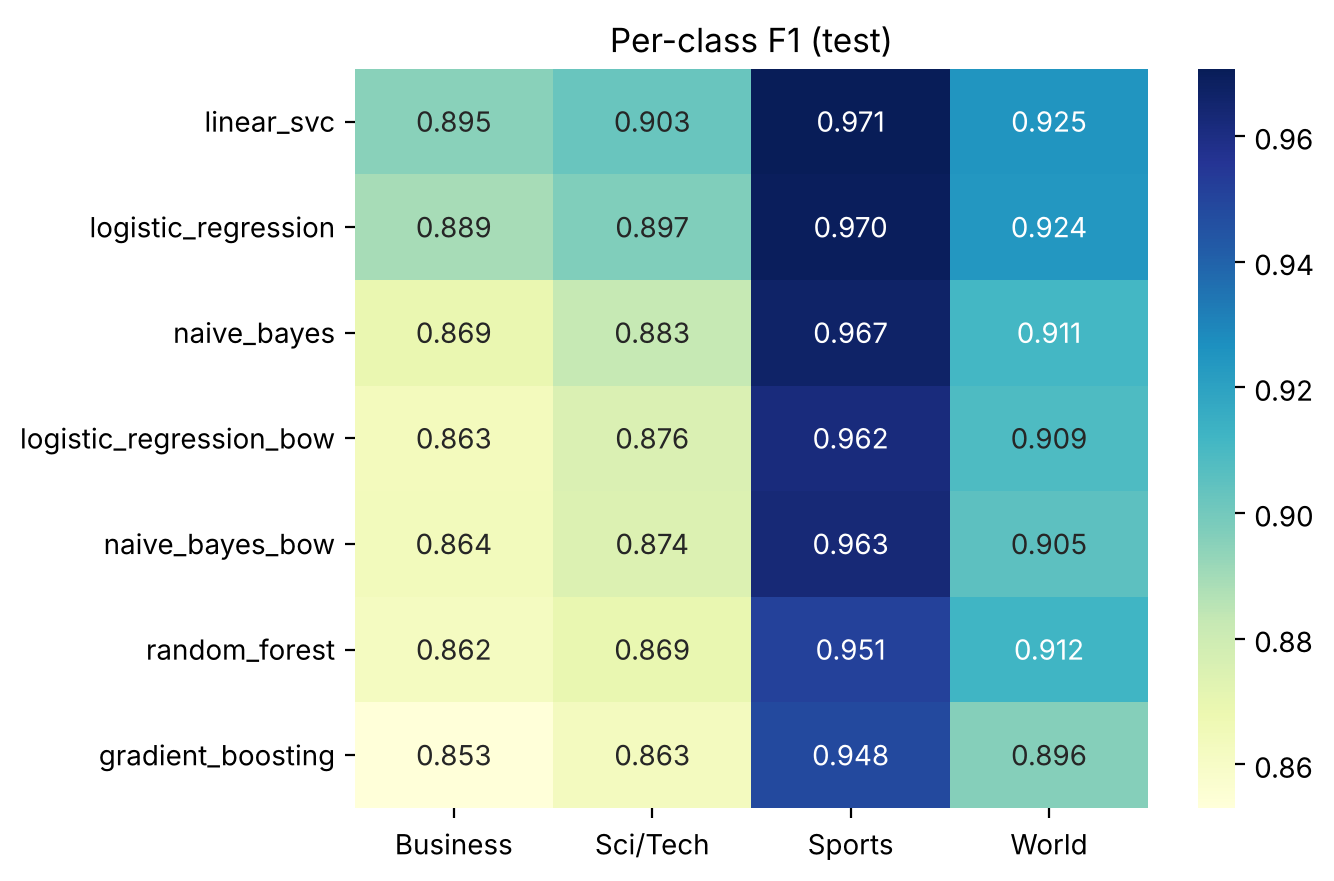

In [4]:
pc = pd.DataFrame({k: {c: v['per_class'][c]['f1-score'] for c in ['Business','Sci/Tech','Sports','World']} for k, v in res.items()}).T.loc[df.index]
sns.heatmap(pc, annot=True, fmt='.3f', cmap='YlGnBu'); plt.title('Per-class F1 (test)'); plt.show()

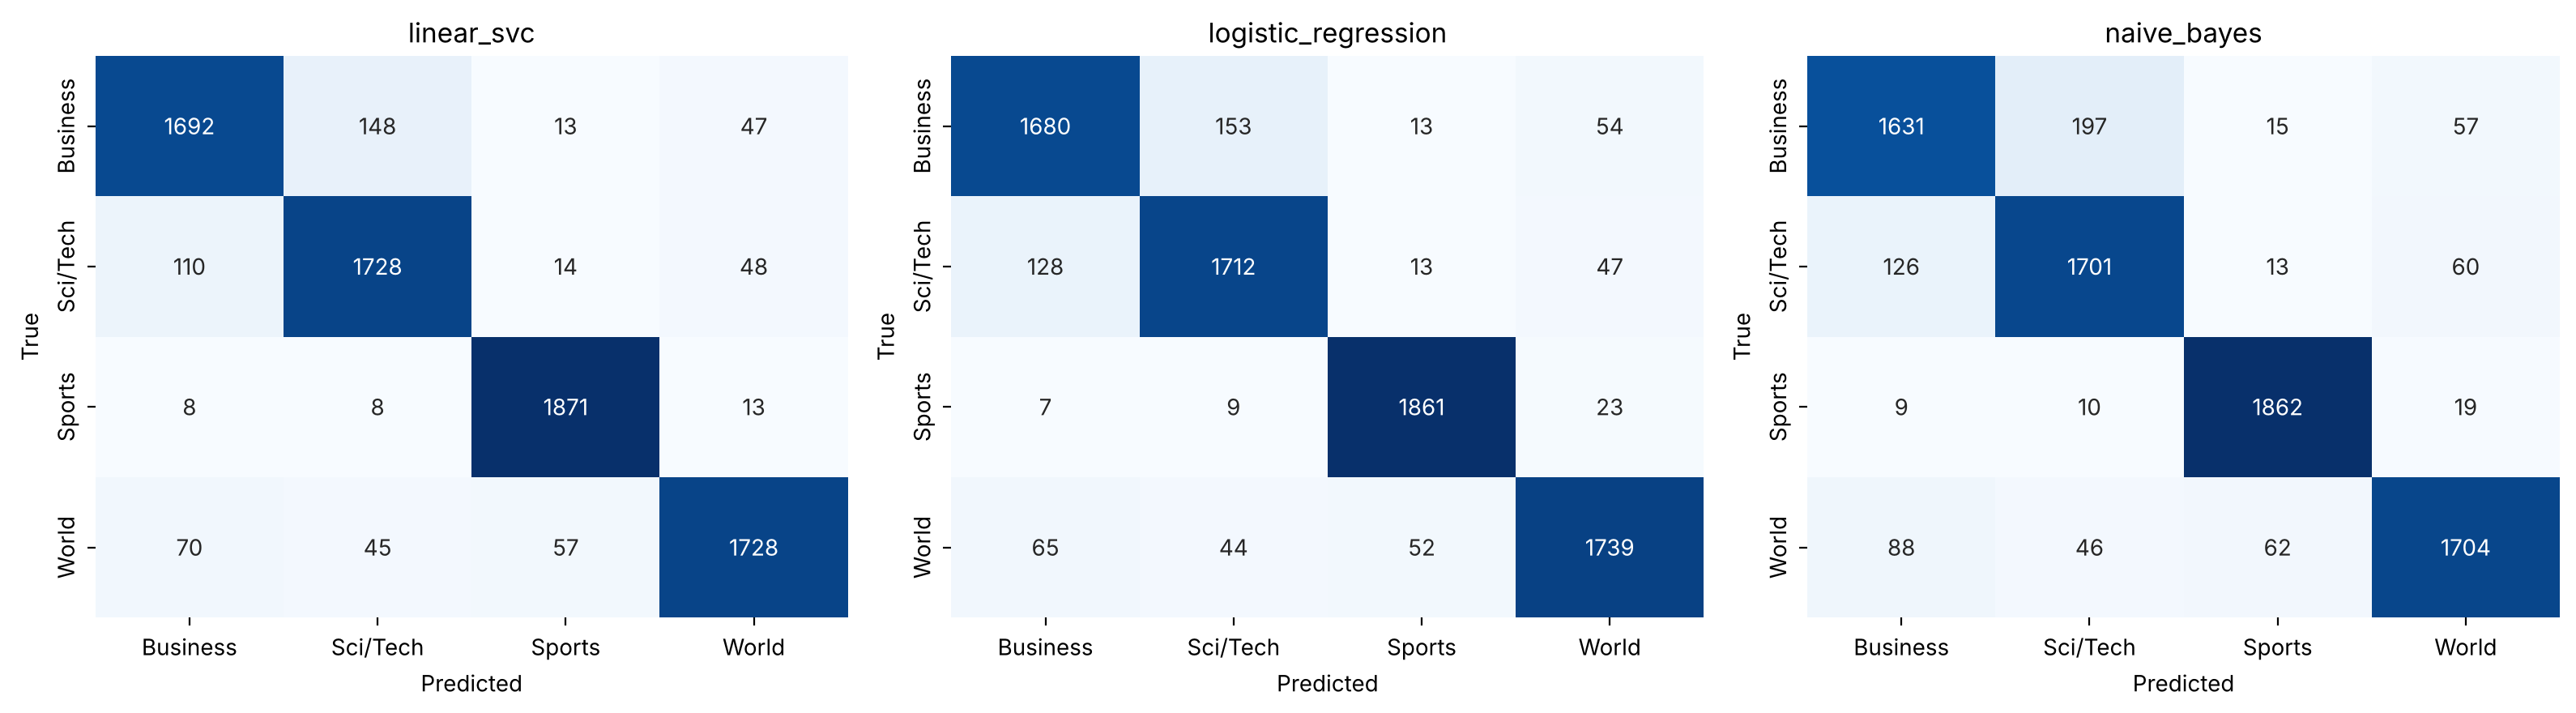

In [5]:
classes = ['Business','Sci/Tech','Sports','World']
top = list(df.index[:3])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, n in zip(axes, top):
    sns.heatmap(res[n]['confusion_matrix'], annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=classes, yticklabels=classes, ax=ax); ax.set_title(n); ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.tight_layout(); plt.savefig('reports/top3_confusion.png', dpi=110); plt.show()

## Selection
We pick the model with the highest weighted F1 on the test set; ties within 0.002 are broken in favour of the faster, more interpretable model. Tuned TF-IDF models are preferred for deployment because the app reuses the TF-IDF vectorizer.

In [6]:
cands = df[df.features.str.startswith('TF-IDF')]
best_f1 = cands.f1.max()
close = cands[cands.f1 >= best_f1 - 0.002]
best = close.sort_values(['predict_ms_per_1000']).index[0]
print('Candidates within 0.002 F1 of the best:', list(close.index)); print('Selected:', best)
df.loc[[best]].round(4)

Candidates within 0.002 F1 of the best: ['linear_svc']
Selected: linear_svc


,features,test_accuracy,precision,recall,f1,f1_macro,val_accuracy,fit_seconds,predict_ms_per_1000
linear_svc,TF-IDF,0.9236,0.9235,0.9236,0.9234,0.9234,0.9292,2.4,0.2


In [7]:
import joblib
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import train_test_split
import scipy.sparse as sp
model = joblib.load(f'models/{best}.joblib')
needs_cal = not hasattr(model, 'predict_proba')
if needs_cal:
    # LinearSVC has no probabilities: calibrate on the training data so the confidence score is meaningful
    X = sp.load_npz('models/features/tfidf_train.npz'); y = np.load('models/features/y_train.npy')
    base = type(model)(**model.get_params())
    model = CalibratedClassifierCV(base, cv=5, method='sigmoid').fit(X, y)
    Xt = sp.load_npz('models/features/tfidf_test.npz'); yt = np.load('models/features/y_test.npy')
    print('calibrated test accuracy:', (model.predict(Xt) == yt).mean())
joblib.dump(model, 'models/best_model.joblib')
r = res[best]
info = {'name': {'linear_svc': 'LinearSVC (calibrated)', 'logistic_regression': 'Logistic Regression', 'naive_bayes': 'Multinomial Naive Bayes'}.get(best, best.replace('_', ' ').title()), 'key': best, 'features': r['features'], 'best_params': r['best_params'],
        'test_accuracy': r['test_accuracy'], 'f1': r['f1'], 'train_size': 120000 if needs_cal else 108000,
        'classes': classes, 'calibrated': needs_cal}
json.dump(info, open('models/model_info.json', 'w'), indent=2); info

calibrated test accuracy: 0.9238157894736843


{'name': 'LinearSVC (calibrated)',
 'key': 'linear_svc',
 'features': 'TF-IDF',
 'best_params': {'C': 0.3},
 'test_accuracy': 0.9235526315789474,
 'f1': 0.9233911447088693,
 'train_size': 120000,
 'classes': ['Business', 'Sci/Tech', 'Sports', 'World'],
 'calibrated': True}

## Prediction system test
`predict(text)` runs: raw text → preprocessing (`src/preprocess.py`) → TF-IDF → best model → category + probabilities.

In [8]:
import sys; sys.path.insert(0, os.getcwd())
from src.predict import predict
samples = {
 'Business': 'Oil prices fell sharply on Tuesday as investors weighed new supply data and the Federal Reserve outlook, pushing stocks lower.',
 'Sports': 'Manchester United edged Chelsea 2-1 in a thrilling league match, with the winning goal scored in the 89th minute by the captain.',
 'Sci/Tech': 'Microsoft released a new version of its Windows software with improved security features for internet users.',
 'World': 'The prime minister said talks with neighbouring countries would continue as the UN called for a ceasefire in the region.',
}
for expected, t in samples.items():
    out = predict(t); print(f"expected={expected:9s} predicted={out['category']:9s} conf={out['confidence']:.2f}")

expected=Business  predicted=Business  conf=0.97
expected=Sports    predicted=Sports    conf=1.00
expected=Sci/Tech  predicted=Sci/Tech  conf=1.00
expected=World     predicted=World     conf=0.94


In [9]:
# overall check: the saved pipeline reproduces the reported test accuracy from raw text
import pandas as pd
test = pd.read_csv('ag_news_test.csv').sample(1000, random_state=1)
preds = [predict(t)['category'] for t in test.text]
print('end-to-end accuracy on 1000 raw test articles:', np.mean(np.array(preds) == test.category.values))

end-to-end accuracy on 1000 raw test articles: 0.928
